# 22. Rekursion (freiwillig)

Eine Funktion darf andere Funktionen aufrufen (Notebook 7). Sie darf aber auch **sich selbst** aufrufen. Das heißt
**Rekursion**. Das klingt verrückt, ist aber ein mächtiges Werkzeug: Manche Probleme lassen sich so beschreiben, dass ein
großes Problem aus kleineren Problemen **derselben Art** besteht. Ein Rechteck enthält zwei kleinere Rechtecke, die wieder zwei
enthalten … Ein Wort aus 5 Buchstaben ist ein Buchstabe und dann ein Wort aus 4 Buchstaben …

In diesem Notebook lernst du:

- wie eine rekursive Funktion aufgebaut ist und warum sie eine **Abbruchbedingung** braucht,
- wie man mit Rekursion **alle Möglichkeiten** durchprobiert, auch wenn man nicht weiß, wie viele Schleifen man bräuchte,
- wie man **Zwischenergebnisse merkt**, damit es schnell bleibt.

In der Wettbewerbs-Ecke berechnest du die Gewinnchance beim Glücksrad und zeichnest einen Rechteck-Bildschirmschoner. Dieses
Notebook ist freiwillig. Rekursion kam in den Junioraufgaben bisher selten vor, vor allem bei den ältesten.

## 1. Eine Funktion ruft sich selbst auf

Ein Countdown von `n` bis 1 ist: „Sag `n`, dann mach einen Countdown von `n - 1`.“ Und ein Countdown von 0 ist: „Sag Start!“.

Jede rekursive Funktion hat zwei Teile:

1. Die **Abbruchbedingung**: ein einfacher Fall, der ohne Selbstaufruf gelöst wird (hier `n == 0`).
2. Der **rekursive Schritt**: Die Funktion ruft sich mit einem **kleineren** Problem selbst auf (hier `n - 1`).

Weil das Problem bei jedem Aufruf kleiner wird, kommt man irgendwann beim einfachen Fall an.

In [ ]:
def countdown(n):
    if n == 0:                  # Abbruchbedingung
        print('Start!')
        return
    print(n)
    countdown(n - 1)            # rekursiver Schritt


countdown(3)

#### Frage 1.1

Was fehlt hier?

```python
def zaehle(n):
    return zaehle(n - 1) + 1

print(zaehle(5))
```

Python meldet: `RecursionError: maximum recursion depth exceeded`

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

Es fehlt die **Abbruchbedingung**. `zaehle(5)` ruft `zaehle(4)` auf, das ruft `zaehle(3)` auf, …, dann `zaehle(-1)`,
`zaehle(-2)` und so weiter, ohne Ende. Python bricht nach etwa 1000 Aufrufen ab (*maximum recursion depth*, größte erlaubte
Verschachtelung). Richtig wäre zum Beispiel `if n == 0: return 0` am Anfang.

</details>

Rekursive Funktionen können auch Werte **zurückgeben**. Die Summe der Zahlen von 1 bis `n` ist `n` plus die Summe von 1 bis
`n - 1`, und die Summe bis 0 ist 0.

#### Aufgabe 1.2: Was wird ausgegeben?

Überlege zuerst, was der Code ausgibt, und schreibe es auf. Führe die Zelle erst danach aus.

In [ ]:
def summe_bis(n):
    if n == 0:
        return 0
    return n + summe_bis(n - 1)


def potenz(basis, exponent):
    if exponent == 0:
        return 1
    return basis * potenz(basis, exponent - 1)


print(summe_bis(4))
print(potenz(2, 10))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
10
1024
```

`summe_bis(4)` ist `4 + summe_bis(3)` = `4 + 3 + summe_bis(2)` = … = `4 + 3 + 2 + 1 + 0` = 10. `potenz(2, 10)` multipliziert
zehnmal mit 2. Beides ginge auch mit einer Schleife. Rekursion lohnt sich erst bei Problemen, bei denen Schleifen nicht reichen.

</details>

#### Aufgabe 1.3

Schreibe die Quersumme (Notebook 4) **rekursiv**: Die Quersumme einer Zahl ist ihre letzte Ziffer plus die Quersumme der Zahl
ohne die letzte Ziffer. Die Quersumme von 0 ist 0.

**Erwartete Ausgabe:**
```
21 0 9
```

In [ ]:
def quersumme(zahl):
    return 0            # ersetze diese Zeile


print(quersumme(4728), quersumme(0), quersumme(9))

<details>
<summary>Tipp anzeigen</summary>

Abbruch: `if zahl == 0: return 0`. Schritt: `return zahl % 10 + quersumme(zahl // 10)`.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def quersumme(zahl):
    if zahl == 0:
        return 0
    return zahl % 10 + quersumme(zahl // 10)


print(quersumme(4728), quersumme(0), quersumme(9))
```

</details>

## 2. Alle Möglichkeiten rekursiv

Alle Wörter aus 3 Buchstaben aus `a` und `b` bekommst du mit drei Schleifen ineinander (Notebook 10). Aber wie viele Schleifen
schreibst du, wenn die Länge erst beim Ausführen feststeht? Mit Rekursion brauchst du gar keine feste Anzahl:

„Alle Wörter der Länge `n`“ heißt: Hänge an den bisherigen Anfang nacheinander jeden Buchstaben an und bilde dann alle Wörter
mit einem Buchstaben weniger. Ist nichts mehr übrig (`n == 0`), ist ein Wort fertig.

In [ ]:
def alle_woerter(anfang, n, buchstaben):
    if n == 0:
        print(anfang, end=' ')
        return
    for b in buchstaben:
        alle_woerter(anfang + b, n - 1, buchstaben)


alle_woerter('', 3, 'ab')
print()
alle_woerter('', 2, 'xyz')
print()

#### Aufgabe 2.1

Ändere die Idee so, dass die Funktion die Wörter nicht ausgibt, sondern **zählt**, wie viele es gibt, und zwar nur die, in
denen **kein Buchstabe zweimal hintereinander** steht. Teste mit Länge 4 aus `abc`.

**Erwartete Ausgabe:**
```
24
```

In [ ]:
def zaehle_woerter(anfang, n, buchstaben):
    return 0            # ersetze diese Zeile


print(zaehle_woerter('', 4, 'abc'))

<details>
<summary>Tipp anzeigen</summary>

Ein fertiges Wort zählt als 1. Sonst zählst du die Ergebnisse der Aufrufe zusammen, aber nur für Buchstaben `b`, die anders sind
als der letzte Buchstabe des Anfangs (`anfang[-1] != b`, bei leerem Anfang ist alles erlaubt).

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def zaehle_woerter(anfang, n, buchstaben):
    if n == 0:
        return 1
    anzahl = 0
    for b in buchstaben:
        if anfang == '' or anfang[-1] != b:
            anzahl = anzahl + zaehle_woerter(anfang + b, n - 1, buchstaben)
    return anzahl


print(zaehle_woerter('', 4, 'abc'))
```

Für den ersten Buchstaben gibt es 3 Möglichkeiten, für jeden weiteren nur 2 (nicht derselbe wie davor): 3 · 2 · 2 · 2 = 24.
Mit so einer Rechnung kannst du dein Programm kontrollieren. Solche Regeln kamen in der Aufgabe „Passwörter“ vor (Notebook 16).

</details>

**Auswählen oder nicht:** Ein anderes häufiges Muster: Für jedes Ding entscheidest du, ob du es **nimmst oder nicht**. Bei `n`
Dingen sind das 2 · 2 · … · 2 Möglichkeiten. Rekursiv: Entscheide über das Ding Nummer `i`, einmal mit und einmal ohne, und
mach dann mit `i + 1` weiter.

Ein Beispiel aus der Aufgabe „Luftballons“ (Bundeswettbewerb Informatik 2016): Eine Verpackungsmaschine hat Fächer mit
verschiedenen Mengen Luftballons. Man soll Fächer so auswählen, dass **mindestens 20** Ballons zusammenkommen, aber möglichst
**genau 20**.

#### Aufgabe 2.2

Schreibe `suche(i, summe, gewaehlt)`, die alle Auswahlen der Fächer durchprobiert und die beste in der Variablen `beste` merkt
(kleinste Summe, die mindestens 20 ist). Sobald eine Auswahl 20 erreicht, muss man nicht mehr weiter hinzunehmen: Es würde nur
mehr.

**Erwartete Ausgabe:**
```
[20, [0, 1, 4, 5]]
Fächer [0, 1, 4, 5] mit [2, 8, 2, 8] Ballons, zusammen 20
```

In [ ]:
faecher = [2, 8, 7, 9, 2, 8, 5]
beste = [999, []]           # beste Summe und die gewählten Fächer


def suche(i, summe, gewaehlt):
    pass                # ersetze diese Zeile


suche(0, 0, [])
print(beste)

<details>
<summary>Tipp anzeigen</summary>

Zwei Abbruchbedingungen: Ist `summe >= 20`, vergleiche mit `beste` und höre auf. Ist `i == len(faecher)`, höre auch auf. Sonst
zwei Aufrufe: einmal mit Fach `i` (`summe + faecher[i]`, `gewaehlt + [i]`), einmal ohne.

Warum ist `beste` eine Liste? Eine Funktion kann eine Liste, die außerhalb angelegt wurde, **verändern** (`beste[0] = ...`),
aber einer äußeren Variablen keinen neuen Wert geben. Das ist ein Trick, damit alle Aufrufe dasselbe Ergebnis teilen.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
faecher = [2, 8, 7, 9, 2, 8, 5]
beste = [999, []]           # beste Summe und die gewählten Fächer


def suche(i, summe, gewaehlt):
    if summe >= 20:                         # genug: merken, wenn besser
        if summe < beste[0]:
            beste[0] = summe
            beste[1] = gewaehlt
        return
    if i == len(faecher):                   # keine Fächer mehr übrig
        return
    suche(i + 1, summe + faecher[i], gewaehlt + [i])     # Fach i nehmen
    suche(i + 1, summe, gewaehlt)                        # Fach i nicht nehmen


suche(0, 0, [])
print(beste)
inhalt = []
for i in beste[1]:
    inhalt.append(faecher[i])
print('Fächer', beste[1], 'mit', inhalt, 'Ballons, zusammen', beste[0])
```

Gefunden wird 2 + 8 + 2 + 8 = 20 aus den Fächern 0, 1, 4 und 5, genau die Auswahl aus dem Beispiel der Aufgabe. Bei 7 Fächern gibt
es höchstens 2 · 2 · 2 · 2 · 2 · 2 · 2 = 128 Auswahlen, die echte Maschine hat 10 Fächer, also 1024. Das ist für den Computer
eine Kleinigkeit. Siehe `jwinf3/35_Luftballons/luftballons_loesung.ipynb`.

</details>

## 3. Zwischenergebnisse merken

Die **Fibonacci-Zahlen** 0, 1, 1, 2, 3, 5, 8, 13, … entstehen, indem man immer die beiden vorigen addiert. Rekursiv
aufgeschrieben ist das ganz einfach. Aber es ist sehr langsam: `fib(30)` ruft `fib(29)` und `fib(28)` auf, `fib(29)` ruft
noch einmal `fib(28)` auf, und so weiter. Dieselben Werte werden immer wieder neu berechnet.

Die Abhilfe: **Merken**. Bevor du rechnest, schaust du in einem Wörterbuch nach, ob das Ergebnis schon bekannt ist. Wenn ja,
gibst du es sofort zurück. Wenn nein, rechnest du es aus und trägst es ein.

#### Aufgabe 3.1

Zähle mit der Liste `aufrufe` (sie enthält eine Zahl, die die Funktionen erhöhen), wie oft `fib_langsam(25)` aufgerufen wird.
Schreibe dann `fib_schnell(n)` mit dem Wörterbuch `gemerkt` und zähle wieder.

**Erwartete Ausgabe:**
```
75025 242785 Aufrufe
75025 49 Aufrufe
354224848179261915075
```

In [ ]:
aufrufe = [0]


def fib_langsam(n):
    aufrufe[0] = aufrufe[0] + 1
    if n < 2:
        return n
    return fib_langsam(n - 1) + fib_langsam(n - 2)


print(fib_langsam(25), aufrufe[0], 'Aufrufe')

gemerkt = {}


def fib_schnell(n):
    return 0            # ersetze diese Zeile

<details>
<summary>Tipp anzeigen</summary>

Am Anfang von `fib_schnell`: `if n in gemerkt: return gemerkt[n]`. Am Ende das Ergebnis mit `gemerkt[n] = ergebnis` eintragen,
dann zurückgeben.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
aufrufe = [0]


def fib_langsam(n):
    aufrufe[0] = aufrufe[0] + 1
    if n < 2:
        return n
    return fib_langsam(n - 1) + fib_langsam(n - 2)


print(fib_langsam(25), aufrufe[0], 'Aufrufe')

gemerkt = {}


def fib_schnell(n):
    aufrufe[0] = aufrufe[0] + 1
    if n in gemerkt:
        return gemerkt[n]
    if n < 2:
        ergebnis = n
    else:
        ergebnis = fib_schnell(n - 1) + fib_schnell(n - 2)
    gemerkt[n] = ergebnis
    return ergebnis


aufrufe[0] = 0
print(fib_schnell(25), aufrufe[0], 'Aufrufe')
print(fib_schnell(100))
```

Statt rund 250 000 Aufrufen sind es nur 49, und selbst `fib(100)` geht sofort. Dieses Merken heißt auf Englisch **Memoization**.
Es ist der Anfang einer wichtigen Technik für schwierigere Wettbewerbsaufgaben, der **dynamischen Programmierung**.

</details>

## Wettbewerbs-Ecke 1: Glücksrad

*Angelehnt an die Junioraufgabe „Glücksrad“ (Bundeswettbewerb Informatik 2011).*

Ein Glücksrad hat 6 Felder A bis F. Bei jedem Drehen bewegt es sich um 1 bis 6 Felder weiter, und zwar mit diesen
Wahrscheinlichkeiten:

| Felder weiter | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| Wahrscheinlichkeit | 5/15 | 4/15 | 3/15 | 2/15 | 1/15 | 0/15 |

Man startet bei Feld A und dreht sechsmal. Den Millionengewinn bekommt, wer dabei **jedes Feld genau einmal** erreicht, zum
Beispiel (A)–C–D–B–E–A–F. Wie groß ist die Gewinnwahrscheinlichkeit?

Rekursiv: Die Chance, von Feld `pos` aus mit den schon besuchten Feldern `besucht` noch zu gewinnen, ist die Summe über alle
möglichen Schritte `k`: Wahrscheinlichkeit von `k` mal die Chance, vom neuen Feld aus zu gewinnen. Neue Felder, die schon besucht
sind, zählen nicht. Sind alle 6 Felder besucht, ist die Chance 1.

Damit das Ergebnis **exakt** ist, rechnen wir mit Brüchen: `Fraction(5, 15)` aus dem Modul `fractions` ist der Bruch 5/15. Python
kürzt automatisch und rechnet ohne Rundungsfehler (Notebook 17).

#### Aufgabe E.1

Schreibe `chance(pos, besucht)` und berechne die Gewinnwahrscheinlichkeit als Bruch und als Kommazahl. Die Felder sind von 0
bis 5 nummeriert, ein Schritt um `k` führt von `pos` nach `(pos + k) % 6` (Notebook 11).

**Erwartete Ausgabe:**
```
796/16875 0.04717037037037037
```

In [ ]:
from fractions import Fraction

p = [Fraction(5, 15), Fraction(4, 15), Fraction(3, 15), Fraction(2, 15), Fraction(1, 15), Fraction(0, 15)]


def chance(pos, besucht):
    return Fraction(0)  # ersetze diese Zeile


g = chance(0, [])
print(g, float(g))

<details>
<summary>Tipp anzeigen</summary>

Abbruch: `if len(besucht) == 6: return Fraction(1)`. Sonst für jedes `k` von 1 bis 6 das neue Feld berechnen und, wenn es noch
nicht besucht ist, `p[k - 1] * chance(neu, besucht + [neu])` aufsummieren. `besucht + [neu]` ist eine **neue** Liste, die alte
bleibt für die anderen Schritte unverändert.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from fractions import Fraction

p = [Fraction(5, 15), Fraction(4, 15), Fraction(3, 15), Fraction(2, 15), Fraction(1, 15), Fraction(0, 15)]


def chance(pos, besucht):
    if len(besucht) == 6:
        return Fraction(1)
    summe = Fraction(0)
    for k in range(1, 7):
        neu = (pos + k) % 6
        if neu not in besucht:
            summe = summe + p[k - 1] * chance(neu, besucht + [neu])
    return summe


g = chance(0, [])
print(g, float(g))
```

Die Chance ist 796/16875, also etwa 4,7 %. Genau diesen Wert nennen die offiziellen Lösungshinweise. Achtung, das Startfeld A
zählt nicht als besucht: Es muss während der sechs Drehungen noch einmal erreicht werden, wie im Beispiel. Die echte Aufgabe
verlangt das für Räder mit bis zu 10 Feldern. Dann hilft das Merken aus Abschnitt 3. Siehe
`jwinf3/30_Gluecksrad/gluecksrad_loesung.ipynb`.

</details>

## Wettbewerbs-Ecke 2: Rechteckschoner (für Schnelle)

*Angelehnt an die Junioraufgabe „Rechteckschoner“ (Bundeswettbewerb Informatik 2011).*

Moni möchte einen Bildschirmschoner: ein Rechteck, das zwei Rechtecke enthält, die jeweils wieder zwei Rechtecke enthalten und so
weiter. Der Zufall soll bestimmen, wo geteilt wird und welche Farbe ein Rechteck hat. Das ist wie gemacht für Rekursion: Ein
Rechteck zeichnen heißt, es selbst zu zeichnen und dann zwei kleinere Rechtecke **auf dieselbe Art** zu zeichnen.

#### Aufgabe E.2

Schreibe `schachtel(x, y, b, h, tiefe)`: Sie zeichnet ein Rechteck in einer zufälligen hellen Farbe. Ist `tiefe` größer als 0,
teilt sie das Innere (mit etwas Rand) an einer zufälligen Stelle zwischen 30 % und 70 % in zwei Teile, längs der längeren
Seite, und ruft sich für beide Teile mit `tiefe - 1` auf. Zeichne mit `tiefe = 4`.

**So etwa sollte dein Bild aussehen:**

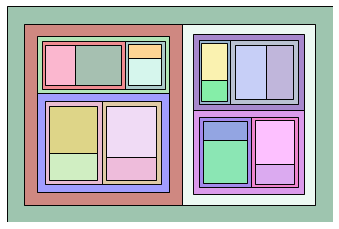

In [ ]:
import random
import matplotlib.pyplot as plt

random.seed(3)


def schachtel(x, y, b, h, tiefe):
    pass                # ersetze diese Zeile


plt.figure(figsize=(6, 4))
schachtel(0, 0, 60, 40, 4)
plt.xlim(0, 60)
plt.ylim(0, 40)
plt.axis('off')
plt.show()

<details>
<summary>Tipp anzeigen</summary>

`random.uniform(a, b)` liefert eine zufällige Kommazahl zwischen a und b. Matplotlib versteht Farben auch als drei Kommazahlen
zwischen 0 und 1, Werte ab 0.5 ergeben helle Farben. Rechtecke zeichnest du wie in Notebook 19 mit `plt.Rectangle`. Erst den Rand
abziehen, dann bei `b >= h` die Breite teilen, sonst die Höhe.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import random
import matplotlib.pyplot as plt

random.seed(3)


def schachtel(x, y, b, h, tiefe):
    farbe = (random.uniform(0.5, 1), random.uniform(0.5, 1), random.uniform(0.5, 1))
    plt.gca().add_patch(plt.Rectangle((x, y), b, h, facecolor=farbe, edgecolor='black'))
    if tiefe == 0:
        return
    rand = 0.08 * min(b, h)
    x, y, b, h = x + rand, y + rand, b - 2 * rand, h - 2 * rand
    teil = random.uniform(0.3, 0.7)
    if b >= h:                                  # senkrecht teilen
        schachtel(x, y, b * teil, h, tiefe - 1)
        schachtel(x + b * teil, y, b * (1 - teil), h, tiefe - 1)
    else:                                       # waagerecht teilen
        schachtel(x, y, b, h * teil, tiefe - 1)
        schachtel(x, y + h * teil, b, h * (1 - teil), tiefe - 1)


plt.figure(figsize=(6, 4))
schachtel(0, 0, 60, 40, 4)
plt.xlim(0, 60)
plt.ylim(0, 40)
plt.axis('off')
plt.show()
```

Mit `tiefe = 4` entstehen 1 + 2 + 4 + 8 + 16 = 31 Rechtecke. Ändere den Startwert von `random.seed`, dann bekommst du ein neues
Bild. Für den echten Bildschirmschoner soll sich danach immer wieder ein Teilrechteck verändern. Siehe
`jwinf3/30_Rechteckschoner/rechteckschoner_loesung.ipynb`.

</details>

## Das hast du gelernt

| Muster | So geht es |
|---|---|
| Rekursion | eine Funktion ruft sich selbst mit einem **kleineren** Problem auf |
| Abbruchbedingung | ein einfacher Fall ohne Selbstaufruf; ohne ihn: `RecursionError` |
| alle Wörter / alle Folgen | für jede Wahl einmal anhängen und mit einem Schritt weniger weitermachen |
| auswählen oder nicht | zwei Aufrufe: einmal mit, einmal ohne das Ding Nummer `i` |
| Ergebnis für alle Aufrufe teilen | eine Liste außerhalb, die die Funktion verändert |
| Zwischenergebnisse merken | Wörterbuch `gemerkt`: erst nachsehen, dann rechnen und eintragen |
| exakte Brüche | `from fractions import Fraction`, `Fraction(5, 15)` |

Damit hast du alle Werkzeug-Notebooks geschafft. Weiter geht es mit Phase D: eine Aufgabe von A bis Z, die Dokumentation und ein
Probewettbewerb.